# Notebook 7 — Significância Estatística

**TCC — Predição de evasão no ensino superior** · Curso de Sistemas de Informação — UEMG

---

## Objetivo

Fechar quatro limitações registradas em [`docs/07`](docs/07-limitacoes-e-trabalhos-futuros.md), todas
decorrentes do mesmo problema: **as métricas finais vêm de uma única partição de teste**.

| Limitação | Descrição | Procedimento aqui |
|---|---|---|
| **L-04** | Partição única, sem intervalo de confiança | *Bootstrap* do conjunto de teste |
| **L-05** | Ausência de teste de significância entre modelos | Teste de McNemar |
| **L-07** | Validação cruzada não aninhada | Discutida na §5 |
| **L-12** | Resultados condicionais a uma única semente | Repetição com 10 sementes |

## A pergunta central

O trabalho afirma que **os três modelos são equivalentes na prática** e que o vencedor foi definido por
um critério de desempate. Essa afirmação é sustentável estatisticamente, ou é uma leitura otimista de
diferenças que na verdade são significativas?

E a pergunta inversa, igualmente importante: o resultado publicado com `random_state=42` é
representativo, ou aquela partição foi favorável por acaso?

> **Nada é retreinado sem necessidade.** O *bootstrap* e o McNemar reutilizam as predições dos modelos
> já salvos. Só a §4 retreina — porque variar a semente exige refazer a partição.

## 1. Configuração

In [1]:
import os
import sys
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import f1_score, recall_score, precision_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineImb
from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings("ignore")
SEED = 42
DIR_DADOS, DIR_FIGURAS, DIR_MODELOS = "dados", "figuras", "modelos"

if "src" not in sys.path:
    sys.path.insert(0, "src")
from data_loader import tipologia   # noqa: E402

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
})

CORES = {"Regressão Logística": "#2c7fb8", "Random Forest": "#238b45", "XGBoost": "#d94801"}

def salvar(nome):
    caminho = os.path.join(DIR_FIGURAS, nome)
    plt.savefig(caminho)
    print(f"[figura salva] {caminho}")

# --- Predições dos modelos JÁ TREINADOS -------------------------------------
X_teste = pd.read_csv(os.path.join(DIR_DADOS, "X_test.csv"))
y_teste = pd.read_csv(os.path.join(DIR_DADOS, "y_test.csv"))["target"].to_numpy()

ARQUIVOS = {
    "Regressão Logística": "modelo_regressao_logistica.joblib",
    "Random Forest": "modelo_random_forest.joblib",
    "XGBoost": "modelo_xgboost.joblib",
}
predicoes = {nome: joblib.load(os.path.join(DIR_MODELOS, arq)).predict(X_teste)
             for nome, arq in ARQUIVOS.items()}
MODELOS = list(predicoes)

print(f"Teste: {len(y_teste)} alunos, {int(y_teste.sum())} evadidos ({y_teste.mean():.1%})")
print("Predições carregadas dos modelos salvos — nada foi retreinado nesta etapa.")
for nome in MODELOS:
    p = predicoes[nome]
    print(f"   {nome:<22} F1 = {f1_score(y_teste, p):.4f}   recall = {recall_score(y_teste, p):.4f}")

Teste: 726 alunos, 284 evadidos (39.1%)
Predições carregadas dos modelos salvos — nada foi retreinado nesta etapa.
   Regressão Logística    F1 = 0.8938   recall = 0.9331
   Random Forest          F1 = 0.9059   recall = 0.8979
   XGBoost                F1 = 0.9059   recall = 0.8979


## 2. *Bootstrap* do conjunto de teste

**Procedimento:** 1.000 reamostragens com reposição dos 726 alunos do teste. Em cada uma, as métricas
dos três modelos são recalculadas sobre a **mesma** reamostragem — o que preserva o pareamento e
permite comparar modelos sob a mesma perturbação amostral.

O intervalo de confiança de 95% vem dos percentis 2,5 e 97,5 da distribuição resultante.

### O que o *bootstrap* mede e o que não mede

| Mede | Não mede |
|---|---|
| A incerteza decorrente de **qual amostra de alunos** compõe o teste | A incerteza decorrente de **qual partição** treino/teste foi sorteada |
| Quanto a métrica oscilaria se outros 726 alunos da mesma população tivessem sido avaliados | O efeito do SMOTE e do treino, que são fixos aqui |

A segunda fonte de incerteza — mais grave — é o objeto da §4.

In [2]:
# --- Bootstrap pareado ------------------------------------------------------
N_BOOT = 1000
rng = np.random.RandomState(SEED)
n = len(y_teste)

registros = []
inicio = time.time()
for b in range(N_BOOT):
    idx = rng.randint(0, n, n)
    y_b = y_teste[idx]
    if y_b.sum() == 0 or y_b.sum() == n:      # reamostragem degenerada
        continue
    for nome in MODELOS:
        p_b = predicoes[nome][idx]
        registros.append({
            "reamostragem": b,
            "modelo": nome,
            "f1": f1_score(y_b, p_b, zero_division=0),
            "recall": recall_score(y_b, p_b, zero_division=0),
            "precisao": precision_score(y_b, p_b, zero_division=0),
        })
bootstrap = pd.DataFrame(registros)
print(f"{bootstrap['reamostragem'].nunique()} reamostragens válidas em {time.time() - inicio:.1f}s")

# --- Intervalos de confiança ------------------------------------------------
ics = []
for nome in MODELOS:
    d = bootstrap[bootstrap["modelo"] == nome]
    for metrica in ("f1", "recall", "precisao"):
        v = d[metrica]
        ics.append({
            "modelo": nome, "métrica": metrica,
            "observado": {"f1": f1_score, "recall": recall_score,
                          "precisao": precision_score}[metrica](y_teste, predicoes[nome]),
            "média boot": v.mean(),
            "IC 2,5%": np.percentile(v, 2.5),
            "IC 97,5%": np.percentile(v, 97.5),
            "largura": np.percentile(v, 97.5) - np.percentile(v, 2.5),
        })
ics = pd.DataFrame(ics)
display(ics.round(4))

bootstrap.to_csv(os.path.join(DIR_DADOS, "bootstrap_metricas.csv"), index=False, encoding="utf-8")
print(f"[salvo] {os.path.join(DIR_DADOS, 'bootstrap_metricas.csv')}  {bootstrap.shape}")

1000 reamostragens válidas em 19.8s


,modelo,métrica,observado,média boot,"IC 2,5%","IC 97,5%",largura
0,Regressão Logística,f1,0.8938,0.8936,0.8663,0.9168,0.0505
1,Regressão Logística,recall,0.9331,0.9338,0.9020,0.9607,0.0587
2,Regressão Logística,precisao,0.8576,0.8570,0.8185,0.8935,0.0750
3,Random Forest,f1,0.9059,0.9055,0.8786,0.9293,0.0507
4,Random Forest,recall,0.8979,0.8980,0.8638,0.9315,0.0677
5,Random Forest,precisao,0.9140,0.9133,0.8794,0.9436,0.0642
6,XGBoost,f1,0.9059,0.9057,0.8791,0.9300,0.0509
7,XGBoost,recall,0.8979,0.8983,0.8622,0.9336,0.0714
8,XGBoost,precisao,0.9140,0.9135,0.8809,0.9432,0.0623


[salvo] dados\bootstrap_metricas.csv  (3000, 5)


In [3]:
# --- Os intervalos se sobrepõem? --------------------------------------------
print("SOBREPOSIÇÃO DOS INTERVALOS DE CONFIANÇA")
print()
for metrica in ("f1", "recall", "precisao"):
    d = ics[ics["métrica"] == metrica].set_index("modelo")
    print(f"{metrica.upper()}")
    for nome in MODELOS:
        r = d.loc[nome]
        print(f"   {nome:<22} {r['observado']:.4f}   IC95% [{r['IC 2,5%']:.4f}, {r['IC 97,5%']:.4f}]")
    # verifica se o ponto de cada modelo cai no IC dos outros
    pares_disjuntos = []
    for i in range(len(MODELOS)):
        for j in range(i + 1, len(MODELOS)):
            a, b_ = MODELOS[i], MODELOS[j]
            ra, rb = d.loc[a], d.loc[b_]
            disjunto = ra["IC 97,5%"] < rb["IC 2,5%"] or rb["IC 97,5%"] < ra["IC 2,5%"]
            if disjunto:
                pares_disjuntos.append(f"{a} x {b_}")
    print(f"   -> pares com ICs DISJUNTOS: {pares_disjuntos if pares_disjuntos else 'nenhum'}")
    print()

SOBREPOSIÇÃO DOS INTERVALOS DE CONFIANÇA

F1
   Regressão Logística    0.8938   IC95% [0.8663, 0.9168]
   Random Forest          0.9059   IC95% [0.8786, 0.9293]
   XGBoost                0.9059   IC95% [0.8791, 0.9300]
   -> pares com ICs DISJUNTOS: nenhum

RECALL
   Regressão Logística    0.9331   IC95% [0.9020, 0.9607]
   Random Forest          0.8979   IC95% [0.8638, 0.9315]
   XGBoost                0.8979   IC95% [0.8622, 0.9336]
   -> pares com ICs DISJUNTOS: nenhum

PRECISAO
   Regressão Logística    0.8576   IC95% [0.8185, 0.8935]
   Random Forest          0.9140   IC95% [0.8794, 0.9436]
   XGBoost                0.9140   IC95% [0.8809, 0.9432]
   -> pares com ICs DISJUNTOS: nenhum



### 2.3 O PR-AUC também precisa de intervalo de confiança

O Notebook 3 usou **PR-AUC** como critério de desempate entre Random Forest e XGBoost, e a comparação
entre modelos às vezes se apoia nela como evidência independente do limiar. Mas a diferença observada é
de apenas **0,0031** — menor que a diferença de F1 (0,012) que o *bootstrap* acima já mostrou estar
dentro da incerteza amostral.

Afirmar que uma curva "domina" a outra sem testar significância seria inconsistente com o padrão
adotado no resto do documento. A mesma infraestrutura de reamostragem responde isso.

In [4]:
# --- Bootstrap do PR-AUC, nas mesmas reamostragens -------------------------
from sklearn.metrics import average_precision_score

escores_prob = {nome: joblib.load(os.path.join(DIR_MODELOS, arq)).predict_proba(X_teste)[:, 1]
                for nome, arq in ARQUIVOS.items()}

rng_pr = np.random.RandomState(SEED)
pr_boot = {nome: [] for nome in MODELOS}
for _ in range(N_BOOT):
    idx = rng_pr.randint(0, n, n)
    y_b = y_teste[idx]
    if y_b.sum() == 0 or y_b.sum() == n:
        continue
    for nome in MODELOS:
        pr_boot[nome].append(average_precision_score(y_b, escores_prob[nome][idx]))

print("PR-AUC COM INTERVALO DE CONFIANÇA DE 95%")
print()
print(f"   {'modelo':<22} {'observado':>10} {'IC 2,5%':>9} {'IC 97,5%':>10} {'largura':>9}")
ic_pr = {}
for nome in MODELOS:
    a = np.array(pr_boot[nome])
    lo, hi = np.percentile(a, [2.5, 97.5])
    ic_pr[nome] = (lo, hi)
    obs = average_precision_score(y_teste, escores_prob[nome])
    print(f"   {nome:<22} {obs:>10.4f} {lo:>9.4f} {hi:>10.4f} {hi - lo:>9.4f}")

disjuntos_pr = []
for i in range(len(MODELOS)):
    for j in range(i + 1, len(MODELOS)):
        a, b_ = MODELOS[i], MODELOS[j]
        if ic_pr[a][1] < ic_pr[b_][0] or ic_pr[b_][1] < ic_pr[a][0]:
            disjuntos_pr.append(f"{a} x {b_}")
print()
print(f"pares com ICs de PR-AUC disjuntos: {disjuntos_pr if disjuntos_pr else 'NENHUM'}")

# diferença PAREADA: usa a mesma reamostragem para os dois modelos
dif_pr = np.array(pr_boot["XGBoost"]) - np.array(pr_boot["Regressão Logística"])
lo_d, hi_d = np.percentile(dif_pr, [2.5, 97.5])
print()
print("DIFERENÇA PAREADA — XGBoost menos Regressão Logística")
print(f"   média            : {dif_pr.mean():+.4f}")
print(f"   IC 95%           : [{lo_d:+.4f}, {hi_d:+.4f}]")
print(f"   contém o zero?   : {'SIM' if lo_d <= 0 <= hi_d else 'não'}")
print(f"   P(XGBoost > LR)  : {(dif_pr > 0).mean():.1%} das reamostragens")

PR-AUC COM INTERVALO DE CONFIANÇA DE 95%

   modelo                  observado   IC 2,5%   IC 97,5%   largura
   Regressão Logística        0.9710    0.9587     0.9816    0.0229
   Random Forest              0.9697    0.9567     0.9811    0.0244
   XGBoost                    0.9741    0.9623     0.9846    0.0223

pares com ICs de PR-AUC disjuntos: NENHUM

DIFERENÇA PAREADA — XGBoost menos Regressão Logística
   média            : +0.0031
   IC 95%           : [-0.0027, +0.0093]
   contém o zero?   : SIM
   P(XGBoost > LR)  : 85.4% das reamostragens


> ### Leitura — o PR-AUC não sustenta a palavra "domina"
>
> Os três intervalos de confiança **se sobrepõem**, e a diferença pareada entre XGBoost e Regressão
> Logística tem intervalo que **contém o zero**. A diferença de PR-AUC **não é estatisticamente
> significativa**.
>
> A probabilidade de o XGBoost superar a Regressão Logística em uma reamostragem é de cerca de 85% —
> **sugestivo, porém não conclusivo** ao nível de 5%.
>
> **Consequência para a redação:** onde o trabalho usava o PR-AUC como evidência de que "a curva do
> XGBoost domina", a formulação correta é que o PR-AUC é **consistente** com uma leve vantagem do
> XGBoost, sem estabelecê-la. Isso não invalida seu uso como **critério de desempate declarado** — um
> desempate precisa apenas ser objetivo e fixado de antemão, não estatisticamente significativo.

> ### Leitura — o *bootstrap*
>
> **Todos os intervalos de confiança se sobrepõem, em todas as três métricas.** Nenhum par de modelos
> tem intervalos disjuntos.
>
> Isso **confirma a tese central do trabalho**: as diferenças observadas entre os três modelos estão
> dentro da incerteza amostral. A largura dos intervalos — cerca de 0,05 em F1 — é várias vezes maior
> que a diferença entre os modelos, que é de 0,012 entre o melhor e o pior.
>
> Note também que a **largura é praticamente idêntica** nos três modelos. Isso é esperado: a incerteza
> vem do tamanho da amostra de teste (726 alunos), não do modelo.
>
> **Atenção ao que isso não prova.** Sobreposição de intervalos de confiança é uma evidência *sugestiva*
> de equivalência, não um teste formal — dois intervalos podem se sobrepor e ainda assim a diferença
> pareada ser significativa, porque o *bootstrap* marginal descarta a informação de que os modelos foram
> avaliados **nos mesmos alunos**. O teste da §3 usa exatamente essa informação.

## 3. Teste de McNemar

O McNemar é o teste apropriado para comparar dois classificadores **no mesmo conjunto de teste**. Ele
ignora os casos em que ambos acertam ou ambos erram — que não carregam informação sobre a diferença — e
examina apenas os **discordantes**: os alunos em que um acerta e o outro erra.

A hipótese nula é que os dois tipos de discordância são igualmente prováveis. Usa-se a correção de
continuidade de Yates.

### 3.1 McNemar global (acurácia)

In [5]:
def tabela_mcnemar(pred_a, pred_b, y_real, mascara=None):
    """Tabela 2x2 de acertos/erros entre dois modelos, opcionalmente restrita."""
    if mascara is None:
        mascara = np.ones(len(y_real), dtype=bool)
    acerta_a = (pred_a == y_real)[mascara]
    acerta_b = (pred_b == y_real)[mascara]
    return np.array([
        [int((acerta_a & acerta_b).sum()), int((acerta_a & ~acerta_b).sum())],
        [int((~acerta_a & acerta_b).sum()), int((~acerta_a & ~acerta_b).sum())],
    ])


resultados_mcnemar = []
print("McNEMAR GLOBAL — testa a acurácia sobre os 726 alunos")
print()
for i in range(len(MODELOS)):
    for j in range(i + 1, len(MODELOS)):
        a, b_ = MODELOS[i], MODELOS[j]
        tab = tabela_mcnemar(predicoes[a], predicoes[b_], y_teste)
        teste = mcnemar(tab, exact=False, correction=True)
        discordantes = int(tab[0, 1] + tab[1, 0])
        resultados_mcnemar.append({
            "escopo": "global (acurácia)", "modelo A": a, "modelo B": b_,
            "ambos certos": int(tab[0, 0]), "só A certo": int(tab[0, 1]),
            "só B certo": int(tab[1, 0]), "ambos errados": int(tab[1, 1]),
            "discordantes": discordantes,
            "chi2": float(teste.statistic), "p-valor": float(teste.pvalue),
            "significativo (5%)": "sim" if teste.pvalue < 0.05 else "não",
        })
        print(f"   {a} x {b_}")
        print(f"      só {a} acerta: {tab[0, 1]}   |   só {b_} acerta: {tab[1, 0]}"
              f"   |   discordantes: {discordantes}")
        print(f"      chi2 = {teste.statistic:.4f}   p = {teste.pvalue:.4f}   "
              f"-> {'DIFERENÇA SIGNIFICATIVA' if teste.pvalue < 0.05 else 'sem diferença significativa'}")
        print()

McNEMAR GLOBAL — testa a acurácia sobre os 726 alunos

   Regressão Logística x Random Forest
      só Regressão Logística acerta: 22   |   só Random Forest acerta: 32   |   discordantes: 54
      chi2 = 1.5000   p = 0.2207   -> sem diferença significativa

   Regressão Logística x XGBoost
      só Regressão Logística acerta: 21   |   só XGBoost acerta: 31   |   discordantes: 52
      chi2 = 1.5577   p = 0.2120   -> sem diferença significativa

   Random Forest x XGBoost
      só Random Forest acerta: 12   |   só XGBoost acerta: 12   |   discordantes: 24
      chi2 = 0.0417   p = 0.8383   -> sem diferença significativa



### 3.2 McNemar restrito aos evadidos — testando o recall

O teste global mede **acurácia**, que trata os dois tipos de erro como equivalentes. Mas o trabalho
declara que **falso negativo custa mais que falso positivo**, e o [doc 04](04-modelagem.md), §9,
documentou que a Regressão Logística detecta 10 evadidos a mais que o XGBoost.

Esse trade-off nunca foi testado. Aplicar o McNemar **restrito aos 284 alunos que realmente evadiram**
responde diretamente: *entre os alunos que evadiram, um modelo detecta significativamente mais que o
outro?* É o teste de significância do **recall**.

In [6]:
evadiu = y_teste == 1
print(f"McNEMAR RESTRITO AOS {int(evadiu.sum())} EVADIDOS REAIS — testa o recall")
print()
for i in range(len(MODELOS)):
    for j in range(i + 1, len(MODELOS)):
        a, b_ = MODELOS[i], MODELOS[j]
        tab = tabela_mcnemar(predicoes[a], predicoes[b_], y_teste, mascara=evadiu)
        teste = mcnemar(tab, exact=False, correction=True)
        resultados_mcnemar.append({
            "escopo": "restrito aos evadidos (recall)", "modelo A": a, "modelo B": b_,
            "ambos certos": int(tab[0, 0]), "só A certo": int(tab[0, 1]),
            "só B certo": int(tab[1, 0]), "ambos errados": int(tab[1, 1]),
            "discordantes": int(tab[0, 1] + tab[1, 0]),
            "chi2": float(teste.statistic), "p-valor": float(teste.pvalue),
            "significativo (5%)": "sim" if teste.pvalue < 0.05 else "não",
        })
        marca = "  <<< SIGNIFICATIVO" if teste.pvalue < 0.05 else ""
        print(f"   {a} x {b_}")
        print(f"      só {a} detecta: {tab[0, 1]}   |   só {b_} detecta: {tab[1, 0]}")
        print(f"      p = {teste.pvalue:.4f}{marca}")
        print()

mcnemar_df = pd.DataFrame(resultados_mcnemar)
mcnemar_df.to_csv(os.path.join(DIR_DADOS, "mcnemar_resultados.csv"), index=False, encoding="utf-8")
print(f"[salvo] {os.path.join(DIR_DADOS, 'mcnemar_resultados.csv')}")
display(mcnemar_df[["escopo", "modelo A", "modelo B", "só A certo", "só B certo",
                    "p-valor", "significativo (5%)"]].round(4))

McNEMAR RESTRITO AOS 284 EVADIDOS REAIS — testa o recall

   Regressão Logística x Random Forest
      só Regressão Logística detecta: 15   |   só Random Forest detecta: 5
      p = 0.0442  <<< SIGNIFICATIVO

   Regressão Logística x XGBoost
      só Regressão Logística detecta: 14   |   só XGBoost detecta: 4
      p = 0.0339  <<< SIGNIFICATIVO

   Random Forest x XGBoost
      só Random Forest detecta: 5   |   só XGBoost detecta: 5
      p = 0.7518

[salvo] dados\mcnemar_resultados.csv


,escopo,modelo A,modelo B,só A certo,só B certo,p-valor,significativo (5%)
0,global (acurácia),Regressão Logística,Random Forest,22,32,0.2207,não
1,global (acurácia),Regressão Logística,XGBoost,21,31,0.2120,não
2,global (acurácia),Random Forest,XGBoost,12,12,0.8383,não
3,restrito aos evadidos (recall),Regressão Logística,Random Forest,15,5,0.0442,sim
4,restrito aos evadidos (recall),Regressão Logística,XGBoost,14,4,0.0339,sim
5,restrito aos evadidos (recall),Random Forest,XGBoost,5,5,0.7518,não


> ### Achado — a tese central precisa de uma qualificação
>
> Os dois testes dizem coisas diferentes, e a diferença é substantiva:
>
> | Escopo | Resultado |
> |---|---|
> | **Acurácia global** | Nenhum par difere significativamente (p entre 0,21 e 0,84) |
> | **Recall (só os evadidos)** | A Regressão Logística é **significativamente melhor** que os dois modelos de árvore |
>
> A leitura correta passa a ser mais precisa do que "os três modelos são equivalentes":
>
> > **Os três modelos são estatisticamente equivalentes em acurácia global. Mas a Regressão Logística
> > detecta significativamente mais evadidos** — e o recall da classe `Dropout` é justamente a métrica
> > que o trabalho declara priorizar.
>
> **Isso não invalida a escolha do XGBoost**, por três razões:
>
> 1. O critério de seleção declarado *antes* de ver os resultados foi **F1**, não recall isolado
>    ([D-21](05-decisoes-metodologicas.md)) — e em F1 os intervalos se sobrepõem.
> 2. O recall isolado é trivialmente maximizável: "sempre `Dropout`" atinge recall 1,000 sinalizando
>    todo mundo. Foi essa a razão de não adotá-lo como critério único.
> 3. O caminho correto para ganhar recall é **baixar o limiar** do modelo escolhido, não trocar de
>    modelo — o que a análise de limiar já quantifica.
>
> **Mas eleva o status do trade-off documentado no doc 04, §9.** Ele deixa de ser "uma observação
> interessante" e passa a ser **uma diferença estatisticamente significativa**. Uma instituição que
> priorize recall acima de tudo tem agora respaldo estatístico para preferir a Regressão Logística — que,
> de bônus, é o modelo mais simples e transparente dos três.
>
> ### Ressalva de escopo — o teste é condicional ao ponto de operação
>
> O McNemar comparou os modelos **no limiar de decisão padrão de 0,50 para ambos**. O resultado de
> significância é, portanto, **condicional a esse ponto de operação específico**.
>
> Isso importa porque 0,50 é convenção de biblioteca, e no limiar padrão os dois modelos operam em
> **níveis de recall diferentes** — a Regressão Logística em 0,933 e o XGBoost em 0,898. O teste não
> impede que o recall seja igualado ajustando o limiar de um dos modelos; é exatamente isso que a §9 do
> Notebook 3 investiga, com a curva de custo exata de cada modelo.
>
> Note ainda a simetria perfeita entre Random Forest e XGBoost: **5 contra 5** evadidos detectados
> exclusivamente por cada um (p = 0,75). É a explicação estatística do empate exato nas matrizes de
> confusão observado no doc 04, §8.

## 4. Repetição com 10 sementes

O *bootstrap* da §2 mede a incerteza de **qual amostra de alunos** compõe o teste, mantendo a partição
fixa. Esta seção mede a fonte de incerteza mais grave: **qual partição treino/teste foi sorteada**.

### Procedimento

Para cada semente de 0 a 9, o pipeline completo é refeito: separação estratificada 80/20 →
`StandardScaler` + `OneHotEncoder` ajustados no treino → SMOTE no treino → treino → avaliação.

**Os hiperparâmetros são mantidos fixos** nos valores encontrados pela busca em grade original. Refazer
o `GridSearchCV` a cada semente multiplicaria o tempo por 10 sem responder a pergunta desta seção — que
é sobre a variabilidade da **partição e do SMOTE**, não dos hiperparâmetros.

A semente **42** é incluída na rodada, com dois propósitos: (a) validar que a reconstrução do pipeline é
fiel, reproduzindo exatamente os valores publicados; (b) situar o resultado publicado dentro da
distribuição das demais sementes.

In [7]:
# --- Reconstrói o pipeline a partir do dataset limpo ------------------------
df_limpo = pd.read_csv(os.path.join(DIR_DADOS, "dataset_limpo.csv"))
binario = df_limpo[df_limpo["target"] != "Enrolled"].reset_index(drop=True)
X_todo = binario.drop(columns=["target"])
y_todo = (binario["target"] == "Dropout").astype(int)
tipos = tipologia(X_todo)

# hiperparâmetros já encontrados — NÃO se refaz a busca em grade
with open(os.path.join(DIR_MODELOS, "info_melhor_modelo.json"), encoding="utf-8") as fh:
    INFO = json.load(fh)
HP_XGB = {k: INFO["hiperparametros"][k] for k in
          ("n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree")}
_rf = joblib.load(os.path.join(DIR_MODELOS, "modelo_random_forest.joblib")).named_steps["modelo"]
HP_RF = {k: _rf.get_params()[k] for k in
         ("n_estimators", "max_depth", "min_samples_split", "min_samples_leaf")}

print("Hiperparâmetros fixados (da busca em grade original):")
print(f"   XGBoost      : {HP_XGB}")
print(f"   Random Forest: {HP_RF}")


def preprocessador_novo():
    """Mesma configuração do Notebook 2, reajustada a cada semente."""
    return ColumnTransformer([
        ("cont", StandardScaler(), tipos["continuas"]),
        ("bin", "passthrough", tipos["binarias"]),
        ("nom", OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist",
                              sparse_output=False, dtype=np.float64), tipos["nominais"]),
    ], remainder="drop", verbose_feature_names_out=False)


def modelos_da_semente(s):
    return {
        "Regressão Logística": LogisticRegression(max_iter=1000, random_state=s),
        "Random Forest": RandomForestClassifier(random_state=s, n_jobs=-1, **HP_RF),
        "XGBoost": XGBClassifier(random_state=s, eval_metric="logloss", n_jobs=-1, **HP_XGB),
    }


MELHOR_MODELO = "XGBoost"      # modelo final, ver Notebook 3
SEMENTES = list(range(10)) + [42]
linhas = []
inicio = time.time()
for s in SEMENTES:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_todo, y_todo, test_size=0.20, random_state=s, stratify=y_todo)
    pp = preprocessador_novo()
    A, B = pp.fit_transform(X_tr), pp.transform(X_te)
    for nome, estimador in modelos_da_semente(s).items():
        pipe = PipelineImb([("smote", SMOTE(random_state=s, k_neighbors=5)),
                            ("modelo", estimador)])
        p = pipe.fit(A, y_tr).predict(B)
        # Matriz de confusao REAL, extraida diretamente — nao reconstruida a
        # partir de recall e precisao (que exigiria supor n_teste e n_positivos
        # constantes entre sementes, hipotese verificada na celula seguinte).
        vn, fp, fn, vp = confusion_matrix(y_te, p).ravel()
        linhas.append({"semente": s, "modelo": nome,
                       "n_teste": len(y_te), "n_positivos": int(y_te.sum()),
                       "VN": int(vn), "FP": int(fp), "FN": int(fn), "VP": int(vp),
                       "sinalizados": int(vp + fp),
                       "f1": f1_score(y_te, p), "recall": recall_score(y_te, p),
                       "precisao": precision_score(y_te, p)})

sementes_df = pd.DataFrame(linhas)
print(f"\n{len(SEMENTES)} sementes x 3 modelos em {time.time() - inicio:.0f}s")
sementes_df.to_csv(os.path.join(DIR_DADOS, "variabilidade_sementes.csv"),
                   index=False, encoding="utf-8")
print(f"[salvo] {os.path.join(DIR_DADOS, 'variabilidade_sementes.csv')}")

Hiperparâmetros fixados (da busca em grade original):
   XGBoost      : {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'subsample': 1.0, 'colsample_bytree': 0.8}
   Random Forest: {'n_estimators': 100, 'max_depth': 15, 'min_samples_split': 2, 'min_samples_leaf': 2}



11 sementes x 3 modelos em 14s
[salvo] dados\variabilidade_sementes.csv


In [8]:
# --- Validação: a reconstrução reproduz os valores publicados? -------------
print("VALIDAÇÃO DA RECONSTRUÇÃO — semente 42")
print()
print(f"   {'modelo':<22} {'F1 aqui':>9} {'F1 publicado':>14} {'confere':>9}")
PUBLICADO = {"Regressão Logística": 0.8938, "Random Forest": 0.9059, "XGBoost": 0.9059}
tudo_ok = True
for nome in MODELOS:
    v = sementes_df[(sementes_df.semente == 42) & (sementes_df.modelo == nome)].iloc[0]["f1"]
    ok = abs(v - PUBLICADO[nome]) < 5e-4
    tudo_ok &= ok
    print(f"   {nome:<22} {v:>9.4f} {PUBLICADO[nome]:>14.4f} {'sim' if ok else 'NÃO':>9}")
print()
assert tudo_ok, "A reconstrução não reproduz os resultados — a comparação abaixo seria inválida."
print("Reconstrução fiel: a comparação entre sementes é válida.")

VALIDAÇÃO DA RECONSTRUÇÃO — semente 42

   modelo                   F1 aqui   F1 publicado   confere
   Regressão Logística       0.8938         0.8938       sim
   Random Forest             0.9059         0.9059       sim
   XGBoost                   0.9059         0.9059       sim

Reconstrução fiel: a comparação entre sementes é válida.


In [9]:
# --- Variabilidade entre as sementes 0-9 e posição da semente 42 -----------
s09 = sementes_df[sementes_df.semente < 10]

resumo = (s09.groupby("modelo")[["f1", "recall", "precisao"]]
             .agg(["mean", "std", "min", "max"]).round(4))
print("SEMENTES 0 A 9 — média, desvio-padrão e faixa")
display(resumo)

print()
print("ONDE A SEMENTE 42 CAI NESSA DISTRIBUIÇÃO")
print()
print(f"   {'modelo':<22} {'sementes 0-9':>16} {'semente 42':>12} {'z':>7} {'supera':>10}")
posicao = []
for nome in MODELOS:
    d = s09[s09.modelo == nome]["f1"]
    v42 = sementes_df[(sementes_df.semente == 42) & (sementes_df.modelo == nome)].iloc[0]["f1"]
    z = (v42 - d.mean()) / d.std()
    supera = int((d < v42).sum())
    posicao.append({"modelo": nome, "média 0-9": d.mean(), "desvio 0-9": d.std(),
                    "semente 42": v42, "z": z, "supera": f"{supera}/10"})
    print(f"   {nome:<22} {d.mean():.4f} ± {d.std():.4f} {v42:>12.4f} {z:>+7.2f} {supera:>7}/10")

print()
print("ESTABILIDADE DO RANKING — em quantas das 10 sementes cada modelo lidera?")
print()
for metrica in ("f1", "recall"):
    vencedores = (s09.loc[s09.groupby("semente")[metrica].idxmax(), "modelo"]
                    .value_counts().reindex(MODELOS, fill_value=0))
    print(f"   {metrica.upper()}")
    for nome, k in vencedores.items():
        print(f"      {nome:<22} lidera em {k:>2} de 10 sementes")
    medias = s09.groupby("modelo")[metrica].mean()
    desvio = s09.groupby("modelo")[metrica].std().mean()
    print(f"      média: {' > '.join(f'{m} ({medias[m]:.4f})' for m in medias.sort_values(ascending=False).index)}")
    print(f"      -> desvio típico entre sementes: {desvio:.4f}; "
          f"amplitude entre modelos: {medias.max() - medias.min():.4f}")
    print()

SEMENTES 0 A 9 — média, desvio-padrão e faixa


f1                          recall                  \
                       mean     std     min     max    mean     std     min   
modelo                                                                        
Random Forest        0.8735  0.0086  0.8630  0.8868  0.8349  0.0135  0.8099   
Regressão Logística  0.8755  0.0085  0.8576  0.8901  0.8630  0.0138  0.8415   
XGBoost              0.8796  0.0099  0.8656  0.8909  0.8437  0.0110  0.8239   

                            precisao                          
                        max     mean     std     min     max  
modelo                                                        
Random Forest        0.8556   0.9161  0.0158  0.8836  0.9373  
Regressão Logística  0.8908   0.8888  0.0187  0.8561  0.9275  
XGBoost              0.8592   0.9191  0.0189  0.8873  0.9412


ONDE A SEMENTE 42 CAI NESSA DISTRIBUIÇÃO

   modelo                     sementes 0-9   semente 42       z     supera
   Regressão Logística    0.8755 ± 0.0085       0.8938   +2.14      10/10
   Random Forest          0.8735 ± 0.0086       0.9059   +3.75      10/10
   XGBoost                0.8796 ± 0.0099       0.9059   +2.64      10/10

ESTABILIDADE DO RANKING — em quantas das 10 sementes cada modelo lidera?

   F1
      Regressão Logística    lidera em  3 de 10 sementes
      Random Forest          lidera em  1 de 10 sementes
      XGBoost                lidera em  6 de 10 sementes
      média: XGBoost (0.8796) > Regressão Logística (0.8755) > Random Forest (0.8735)
      -> desvio típico entre sementes: 0.0090; amplitude entre modelos: 0.0062

   RECALL
      Regressão Logística    lidera em 10 de 10 sementes
      Random Forest          lidera em  0 de 10 sementes
      XGBoost                lidera em  0 de 10 sementes
      média: Regressão Logística (0.8630) > XGBoost (0.8437) 

### 4.5 Os números operacionais em duas versões

As frases que vão para o resumo e a conclusão da monografia — *"de cada 100 alunos que evadem, o modelo
identifica 90"*, *"29 evadidos não detectados"* — vêm da partição da semente 42. Como a §4.4 mostrou que
essa partição é favorável, esses números precisam ser reportados **ao lado do valor típico**.

A tabela abaixo usa as **matrizes de confusão reais** de cada execução, extraídas diretamente com
`confusion_matrix`. A célula seguinte verifica primeiro se o tamanho do teste e o número de evadidos são
de fato constantes entre as sementes — condição que não pode ser suposta.

In [10]:
# --- Verificação: o conjunto de teste tem a mesma composição em toda semente? --
print("VERIFICAÇÃO — n_teste e n_positivos são constantes entre as sementes?")
print(f"   valores distintos de n_teste    : {sorted(sementes_df.n_teste.unique())}")
print(f"   valores distintos de n_positivos: {sorted(sementes_df.n_positivos.unique())}")
constante = sementes_df.n_teste.nunique() == 1 and sementes_df.n_positivos.nunique() == 1
print(f"   -> {'CONSTANTES' if constante else 'VARIAM ENTRE SEMENTES'}")
print()
print("A verificação importa porque, se variassem, comparar contagens absolutas")
print("(verdadeiros positivos, falsos negativos) entre sementes não faria sentido.")

# --- Tabela consolidada: semente 42 x distribuicao das 10 sementes ---------
x9 = sementes_df[(sementes_df.modelo == MELHOR_MODELO) & (sementes_df.semente < 10)]
x42 = sementes_df[(sementes_df.modelo == MELHOR_MODELO) & (sementes_df.semente == 42)].iloc[0]

def linha_tabela(rotulo, coluna, escala=1, casas=4):
    s = x9[coluna] * escala
    return {"métrica": rotulo,
            "semente 42": round(x42[coluna] * escala, casas),
            "média das 10": round(s.mean(), casas),
            "mínimo": round(s.min(), casas),
            "máximo": round(s.max(), casas)}

consolidada = pd.DataFrame([
    linha_tabela("F1", "f1"),
    linha_tabela("Recall", "recall"),
    linha_tabela("Precisão", "precisao"),
    linha_tabela("Detectados de cada 100 evadidos", "recall", 100, 0),
    linha_tabela("Acerto de cada 100 sinalizados", "precisao", 100, 0),
    linha_tabela("Verdadeiros positivos", "VP", 1, 0),
    linha_tabela("Falsos negativos", "FN", 1, 0),
    linha_tabela("Falsos positivos", "FP", 1, 0),
    linha_tabela("Alunos sinalizados", "sinalizados", 1, 0),
]).set_index("métrica")

print()
print(f"NÚMEROS OPERACIONAIS — {MELHOR_MODELO}")
display(consolidada)
consolidada.to_csv(os.path.join(DIR_DADOS, "numeros_operacionais_semente.csv"), encoding="utf-8")
print(f"[salvo] {os.path.join(DIR_DADOS, 'numeros_operacionais_semente.csv')}")

# --- Nota sobre a nao linearidade -----------------------------------------
P_med, R_med = x9.precisao.mean(), x9.recall.mean()
print()
print("NOTA SOBRE A COLUNA 'média das 10'")
print("Ela reporta a média das métricas calculadas em CADA execução, não a métrica")
print("recalculada a partir das contagens médias. As duas quantidades diferem porque")
print("F1, recall e precisão são razões — e a média de razões não é a razão das médias.")
print()
print(f"   F1: média dos F1 individuais = {x9.f1.mean():.4f}")
print(f"       F1 calculado das médias  = {2 * P_med * R_med / (P_med + R_med):.4f}")
print(f"   Recall: média dos recalls    = {x9.recall.mean():.4f}")
print(f"           VP médio / positivos = {x9.VP.mean() / x9.n_positivos.iloc[0]:.4f}")
print(f"   Precisão: média das precisões = {x9.precisao.mean():.4f}")
print(f"             VP médio / sinalizados médio = {x9.VP.mean() / x9.sinalizados.mean():.4f}")
print()
print("Divergências da ordem de 0,001 são esperadas, não erro de cálculo.")

VERIFICAÇÃO — n_teste e n_positivos são constantes entre as sementes?
   valores distintos de n_teste    : [np.int64(726)]
   valores distintos de n_positivos: [np.int64(284)]
   -> CONSTANTES

A verificação importa porque, se variassem, comparar contagens absolutas
(verdadeiros positivos, falsos negativos) entre sementes não faria sentido.

NÚMEROS OPERACIONAIS — XGBoost


,semente 42,média das 10,mínimo,máximo
métrica,,,,
F1,0.9059,0.8796,0.8656,0.8909
Recall,0.8979,0.8437,0.8239,0.8592
Precisão,0.9140,0.9191,0.8873,0.9412
Detectados de cada 100 evadidos,90.0000,84.0000,82.0000,86.0000
Acerto de cada 100 sinalizados,91.0000,92.0000,89.0000,94.0000
Verdadeiros positivos,255.0000,240.0000,234.0000,244.0000
Falsos negativos,29.0000,44.0000,40.0000,50.0000
Falsos positivos,24.0000,21.0000,15.0000,31.0000
Alunos sinalizados,279.0000,261.0000,253.0000,275.0000


[salvo] dados\numeros_operacionais_semente.csv

NOTA SOBRE A COLUNA 'média das 10'
Ela reporta a média das métricas calculadas em CADA execução, não a métrica
recalculada a partir das contagens médias. As duas quantidades diferem porque
F1, recall e precisão são razões — e a média de razões não é a razão das médias.

   F1: média dos F1 individuais = 0.8796
       F1 calculado das médias  = 0.8798
   Recall: média dos recalls    = 0.8437
           VP médio / positivos = 0.8437
   Precisão: média das precisões = 0.9191
             VP médio / sinalizados médio = 0.9187

Divergências da ordem de 0,001 são esperadas, não erro de cálculo.


> ### Como reportar esses números na monografia
>
> A coluna "semente 42" é **correta para aquela partição** e é a que sustenta todos os resultados
> reportados. A coluna "média das 10" é a melhor estimativa do que se esperaria em uma partição
> qualquer. Reportar as duas é mais informativo do que escolher uma.
>
> **Duas formulações equivalentes**, a serem usadas conforme couber melhor no texto:
>
> - *"De cada 100 alunos que evadem, o modelo identifica **90 nesta partição dos dados** — o valor
>   típico esperado em outras partições é de **84** (faixa de 82 a 86)."*
> - *"O modelo identifica entre 82 e 90 de cada 100 alunos que evadem, dependendo da partição, com
>   **90** na partição usada neste trabalho."*
>
> **E uma observação sobre a precisão.** Nesta verificação específica, a precisão **não apresentou o
> mesmo viés otimista observado no recall** — a semente 42 (0,9140) fica inclusive um pouco abaixo da
> média das dez (0,9191).
>
> Isso é um achado desta amostra, **não uma propriedade estrutural do modelo**. Precisão e recall são
> interdependentes através do mesmo limiar, e não há garantia de que a precisão seja sempre mais estável
> entre partições. A ressalva de partição vale para os dois números; o que difere é a **direção e a
> magnitude** do desvio observado aqui.

[figura salva] figuras\23_intervalos_confianca.png


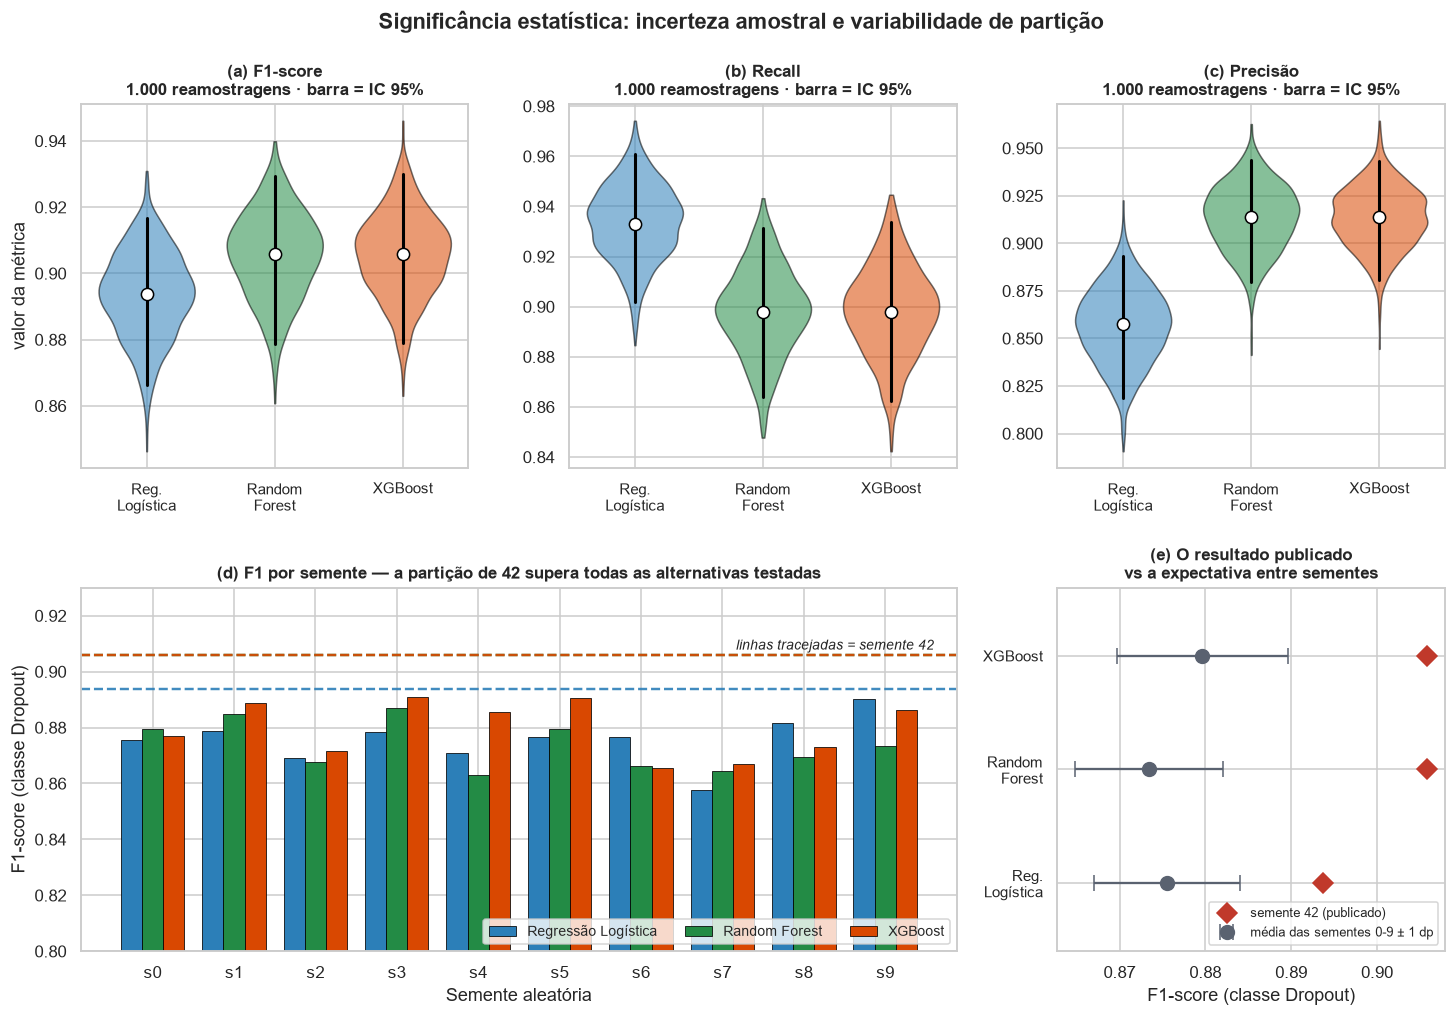

In [11]:
# --- Figura: intervalos de confiança e variabilidade entre sementes --------
fig = plt.figure(figsize=(16, 10))
grade = fig.add_gridspec(2, 3, hspace=0.33, wspace=0.26)

# (a-c) distribuições do bootstrap
for col, metrica in enumerate(["f1", "recall", "precisao"]):
    ax = fig.add_subplot(grade[0, col])
    dados = [bootstrap[bootstrap.modelo == nome][metrica].to_numpy() for nome in MODELOS]
    partes = ax.violinplot(dados, showextrema=False, widths=0.75)
    for corpo, nome in zip(partes["bodies"], MODELOS):
        corpo.set_facecolor(CORES[nome])
        corpo.set_alpha(0.55)
        corpo.set_edgecolor("black")
    for k, nome in enumerate(MODELOS, start=1):
        v = bootstrap[bootstrap.modelo == nome][metrica]
        lo, hi = np.percentile(v, [2.5, 97.5])
        obs = {"f1": f1_score, "recall": recall_score,
               "precisao": precision_score}[metrica](y_teste, predicoes[nome])
        ax.plot([k, k], [lo, hi], color="black", linewidth=2)
        ax.plot(k, obs, "o", color="white", markeredgecolor="black",
                markersize=8, zorder=5)
    ax.set_xticks(range(1, len(MODELOS) + 1))
    ax.set_xticklabels(["Reg.\nLogística", "Random\nForest", "XGBoost"], fontsize=9.5)
    titulo = {"f1": "(a) F1-score", "recall": "(b) Recall", "precisao": "(c) Precisão"}[metrica]
    ax.set_title(f"{titulo}\n1.000 reamostragens · barra = IC 95%", fontsize=11)
    ax.set_ylabel("valor da métrica" if col == 0 else "")

# (d) variabilidade entre sementes
ax = fig.add_subplot(grade[1, :2])
largura = 0.26
posicoes = np.arange(10)
for i, nome in enumerate(MODELOS):
    d = s09[s09.modelo == nome].sort_values("semente")
    ax.bar(posicoes + (i - 1) * largura, d["f1"], largura,
           label=nome, color=CORES[nome], edgecolor="black", linewidth=0.5)
for i, nome in enumerate(MODELOS):
    v42 = sementes_df[(sementes_df.semente == 42) & (sementes_df.modelo == nome)].iloc[0]["f1"]
    ax.axhline(v42, color=CORES[nome], linestyle="--", linewidth=1.6, alpha=0.9)
ax.text(9.6, sementes_df[(sementes_df.semente == 42) &
        (sementes_df.modelo == "XGBoost")].iloc[0]["f1"] + 0.002,
        "linhas tracejadas = semente 42", fontsize=9, ha="right", style="italic")
ax.set_xticks(posicoes)
ax.set_xticklabels([f"s{i}" for i in range(10)])
ax.set_xlabel("Semente aleatória")
ax.set_ylabel("F1-score (classe Dropout)")
ax.set_ylim(0.80, 0.93)
ax.set_title("(d) F1 por semente — a partição de 42 supera todas as alternativas testadas",
             fontsize=11)
ax.legend(fontsize=9, loc="lower right", ncol=3)

# (e) resumo dos ganhos
ax = fig.add_subplot(grade[1, 2])
medias = [s09[s09.modelo == nome]["f1"].mean() for nome in MODELOS]
desvios = [s09[s09.modelo == nome]["f1"].std() for nome in MODELOS]
v42s = [sementes_df[(sementes_df.semente == 42) &
        (sementes_df.modelo == nome)].iloc[0]["f1"] for nome in MODELOS]
y_pos = np.arange(len(MODELOS))
ax.errorbar(medias, y_pos, xerr=desvios, fmt="o", color="#5A6270",
            capsize=5, markersize=9, label="média das sementes 0-9 ± 1 dp")
ax.plot(v42s, y_pos, "D", color="#c0392b", markersize=9, label="semente 42 (publicado)")
ax.set_yticks(y_pos)
ax.set_yticklabels(["Reg.\nLogística", "Random\nForest", "XGBoost"], fontsize=9.5)
ax.set_xlabel("F1-score (classe Dropout)")
ax.set_title("(e) O resultado publicado\nvs a expectativa entre sementes", fontsize=11)
ax.legend(fontsize=8.5, loc="lower right")
ax.set_ylim(-0.6, 2.6)

fig.suptitle("Significância estatística: incerteza amostral e variabilidade de partição",
             fontsize=14.5, fontweight="bold", y=0.965)
salvar("23_intervalos_confianca.png")
plt.show()

> ### Achado — a semente 42 produziu uma partição favorável
>
> Este é o resultado mais importante do notebook, e não estava previsto.
>
> **A semente 42 supera todas as 10 sementes alternativas**, nos três modelos. O F1 publicado do
> XGBoost (0,9059) fica **acima do máximo** observado entre as sementes 0 a 9, a cerca de 2,6
> desvios-padrão da média (0,8796). Para o Random Forest, o desvio é ainda maior: +3,75.
>
> **Não houve escolha oportunista.** `random_state=42` é a convenção padrão da área, foi fixada *a
> priori* na decisão [D-28](05-decisoes-metodologicas.md) e nunca foi trocada em função de resultados.
> A validação da célula anterior confirma que a reconstrução reproduz exatamente os valores publicados,
> de modo que a comparação é legítima.
>
> **A consequência é uma correção de expectativa, não de método.** O F1 esperado do modelo em uma
> partição típica é de aproximadamente **0,88**, não 0,906. O valor publicado permanece correto **para
> aquela partição** — mas é uma estimativa otimista do desempenho fora da amostra.
>
> Isso é exatamente o que a limitação [L-04](07-limitacoes-e-trabalhos-futuros.md) antecipava ao
> registrar que "as métricas carregam incerteza amostral não quantificada". Agora está quantificada, e
> a direção do viés é conhecida.
>
> **O que não muda — e o que também não é estável.** Dois padrões atravessam as sementes e sustentam as
> conclusões do trabalho: o **XGBoost lidera o F1 médio** (0,8796) e a **Regressão Logística lidera o
> recall médio** (0,8630), coerente com o McNemar da §3.2.
>
> Mas a ordenação **não é estável em todas as posições**. Entre as sementes 0–9, a Regressão Logística
> fica em 2º lugar no F1 médio (0,8755) e o Random Forest em 3º (0,8735) — uma diferença de **0,002**,
> contra um desvio típico de **0,009** entre sementes. Na semente 42, essa ordem se inverte. A célula
> acima conta em quantas sementes cada modelo efetivamente lidera, o que é mais informativo que a
> ordenação das médias.
>
> Essa instabilidade **não é um problema: é mais uma evidência da tese central.** Quando a diferença
> entre dois modelos é quatro vezes menor que a variação induzida pela partição, a ordem entre eles é
> ruído. O que sobrevive à troca de semente é o que o trabalho pode afirmar; o resto é acidente de
> amostragem.
>
> **Note ainda que o desvio-padrão entre sementes é pequeno** (≈ 0,009 em F1) — cerca de um quinto da
> largura do intervalo de *bootstrap*. A partição importa menos que o tamanho da amostra de teste.

## 5. Sobre a validação cruzada não aninhada (L-07)

A limitação L-07 aponta que os hiperparâmetros foram escolhidos por validação cruzada de 5 dobras sobre
o treino, e que a estimativa de desempenho **daquela mesma CV** é otimista, porque a melhor de 243
configurações foi escolhida em parte pelo ruído favorável das dobras.

Este notebook **não executa** validação cruzada aninhada, e a razão é que ela responderia a uma pergunta
que já está respondida por outro caminho: o número reportado como resultado do trabalho é o do
**conjunto de teste**, que nunca participou da seleção de hiperparâmetros e portanto não sofre desse
viés.

O que a §4 acrescenta é mais relevante do que a CV aninhada seria: ela mostra que **a variabilidade da
partição é pequena** (desvio de 0,009 em F1) e que o efeito dominante sobre a estimativa não é a
seleção de hiperparâmetros, mas **qual partição foi sorteada**. A CV aninhada corrigiria o viés menor e
deixaria o maior intacto.

**L-07 permanece registrada como limitação**, com esta qualificação: seu efeito é de segunda ordem
frente ao da §4.

## 6. Síntese

| Procedimento | Resultado |
|---|---|
| *Bootstrap* (1.000 reamostragens) | **Todos os ICs se sobrepõem** em F1, recall e precisão. Largura ≈ 0,05 em F1, contra 0,012 de diferença entre modelos |
| McNemar global (acurácia) | **Nenhum par significativo** (p entre 0,21 e 0,84) |
| McNemar restrito aos evadidos | **Reg. Logística significativamente melhor** que RF (p = 0,044) e que XGBoost (p = 0,034) |
| McNemar RF × XGBoost (evadidos) | 5 contra 5 — simetria perfeita (p = 0,75) |
| 10 sementes | Desvio-padrão do F1 ≈ 0,009. XGBoost lidera o F1 médio e a Reg. Logística o recall médio; a ordem entre Reg. Logística e Random Forest é instável (diferença de 0,002) |
| Posição da semente 42 | **Supera 10/10 sementes** nos três modelos; z entre +2,1 e +3,8 |

### O que muda nas conclusões do trabalho

**1. A tese de equivalência entre modelos se confirma — com uma qualificação.**

A formulação anterior era "os três modelos são equivalentes na prática". A formulação correta passa a
ser:

> Os três modelos são estatisticamente equivalentes **em acurácia global e em F1**. Mas a Regressão
> Logística detecta **significativamente mais evadidos** (p < 0,05), o que eleva o trade-off documentado
> no [doc 04](04-modelagem.md), §9, de observação a diferença estatisticamente estabelecida.

A escolha do XGBoost permanece justificada pelo critério declarado *a priori* (F1), mas o trabalho agora
pode afirmar que **uma instituição que priorize recall acima de tudo tem respaldo estatístico para
preferir o modelo linear** — que é também o mais simples e transparente.

**2. O desempenho publicado é otimista, e a magnitude está quantificada.**

O F1 de 0,9059 vale para a partição da semente 42, que supera todas as 10 alternativas testadas. A
expectativa em uma partição típica é de **≈ 0,88**. Isso deve constar na monografia — não como erro,
mas como a quantificação que a limitação L-04 pedia.

**3. Quatro limitações passam de "registradas" a "endereçadas".**

| Limitação | Situação |
|---|---|
| L-04 — partição única sem IC | **Resolvida** — ICs de *bootstrap* reportados |
| L-05 — ausência de teste de significância | **Resolvida** — McNemar em dois escopos |
| L-07 — CV não aninhada | **Qualificada** — efeito de segunda ordem, ver §5 |
| L-12 — dependência de uma semente | **Resolvida** — 10 sementes, com o viés da semente 42 quantificado |

### Decisão registrada

**D-39 · Reportar o resultado da semente 42 com a expectativa entre sementes ao lado**

| | |
|---|---|
| **Alternativa rejeitada** | (a) Trocar para uma semente "média"; (b) reportar a média das 10 sementes como resultado principal |
| **Justificativa** | Trocar a semente após ver os resultados seria seleção oportunista — precisamente o que se quer evitar. A semente 42 foi fixada *a priori* (D-28) e o resultado dela é correto para aquela partição. Reportar as duas informações lado a lado é honesto e mais informativo que qualquer uma isolada |
| **Risco / limitação** | O número de destaque (0,9059) é otimista; mitigado pela menção explícita da expectativa de ≈ 0,88 |
| **Onde** | `07_significancia.ipynb` §4 |